# 1.4 Endemic SIR: Births & Deaths

In our basic SIR model, the population was completely closed—nobody was born and nobody died. Over longer timescales, however, **births and immigration ($\lambda$)** continually add new susceptible individuals, while **natural deaths and emigration ($\mu$)** remove people from every compartment.

This gives us the **Endemic SIR model**!

## Model Diagram & Equations

![Endemic SIR compartmental model](../images/endemic-sir-diagram.svg)

Each compartment now includes demographic turnover:

$$
\begin{aligned}
\frac{dS}{dt} &= \lambda - r \beta S I - \mu S \\
\frac{dI}{dt} &= r \beta S I - \gamma I - \mu I \\
\frac{dR}{dt} &= \gamma I - \mu R
\end{aligned}
$$

- **$\lambda$** — Birth and immigration rate entering the Susceptible ($S$) compartment
- **$\mu$** — Natural death and emigration rate leaving $S$, $I$, and $R$

## Step 1: Load Julia Packages

In [ ]:
using DifferentialEquations
using Plots
println("Ready for Endemic SIR simulation!")

Ready for Endemic SIR simulation!

## Step 2: Run the Baseline Endemic SIR Simulation

Run the cell below to simulate the endemic SIR model over 200 days. Notice what happens to the total population when births ($\lambda = 100/6$) are much smaller than deaths ($\mu \cdot N = \frac{1}{60} \times 6 \times 10^7 = 10^6$)!

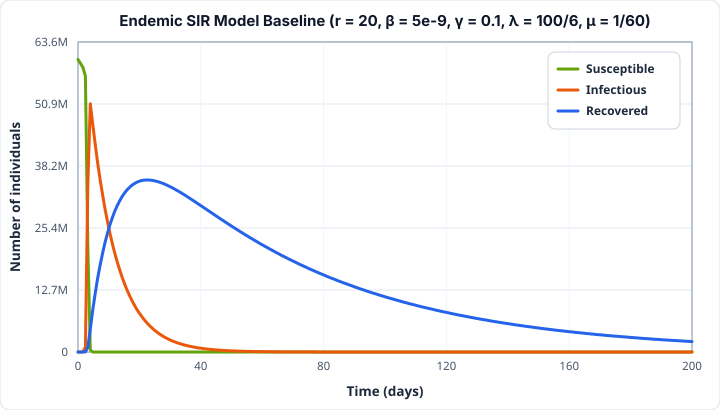

In [ ]:
# Define parameters
r      = 20       # Number of contacts per unit time
beta   = 5e-9     # Probability of disease transmission
gamma  = 0.1      # Recovery rate (try 0.12 or 0.07)
lambda = 100 / 6  # Birth and immigration inflow
mu     = 1 / 60   # Natural death and emigration rate
N      = 6e7      # Initial population size

# Define differential equations
function eSIR!(du, u, p, t)
    r, beta, gamma, lambda, mu = p
    du[1] = lambda - r * beta * u[1] * u[2] - mu * u[1]   # dS/dt
    du[2] =          r * beta * u[1] * u[2] - gamma * u[2] - mu * u[2]  # dI/dt
    du[3] =                                   gamma * u[2] - mu * u[3]  # dR/dt
end

# Initial conditions, parameters, and time span
u0    = [N - 1.0, 1.0, 0.0]
p     = [r, beta, gamma, lambda, mu]
tspan = (0.0, 200.0)

# Solve ODE & plot
prob = ODEProblem(eSIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="Endemic SIR Model (λ=$(round(lambda, digits=1)), μ=$(round(mu, digits=4)))",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

## Challenge: Keeping a Stable Population (Births = Deaths)

In the baseline simulation above, `lambda = 100/6` (~16.7 births/day) while `mu = 1/60` causes ~1,000,000 deaths/day initially—so the entire population shrinks rapidly!

**Your task:** Set births equal to natural deaths (`lambda = mu * N`, keeping total population constant at $N = 6 \times 10^7$) and extend `tspan` to `(0.0, 300.0)`. What happens to the **Susceptible** and **Infectious** curves when new births keep replenishing $S$?

In [ ]:
# Challenge starter code — balance births (lambda) with deaths (mu * N)!
r      = 20
beta   = 5e-9
gamma  = 0.1
mu     = 1 / 60
N      = 6e7
lambda = 100 / 6   # <-- Try setting lambda = mu * N (balanced population)!

u0    = [N - 1.0, 1.0, 0.0]
p     = [r, beta, gamma, lambda, mu]
tspan = (0.0, 200.0)   # <-- Try (0.0, 300.0)

prob = ODEProblem(eSIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="Endemic SIR Challenge (λ=$(round(lambda, digits=1)))",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} Hint — Balanced Births & Deaths
:class: tip, dropdown

Change `lambda = 100 / 6` to `lambda = mu * N` so that total births per unit time match total deaths (`mu * N`), keeping $S + I + R = N$ constant! You can also try lowering `r` to `2` to see classic slower damped epidemic waves.
````

````{admonition} Reveal Solution — Balanced Births & Deaths
:class: note, dropdown

When `lambda = mu * N`, the total population stays constant and newborn susceptibles continuously refuel the infection, producing **damped oscillations** that settle into a true **endemic steady state** (just like childhood diseases such as measles before vaccination!).

```julia
r      = 2         # Moderate contact rate to clearly see endemic waves
beta   = 5e-9
gamma  = 0.1
mu     = 1 / 60
N      = 6e7
lambda = mu * N    # Births balance deaths -> constant total population N

u0    = [N - 1.0, 1.0, 0.0]
p     = [r, beta, gamma, lambda, mu]
tspan = (0.0, 300.0)

prob = ODEProblem(eSIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="Endemic SIR Solution (Balanced Population)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

---

**Next:** Real infections rarely make someone immediately contagious the instant they are exposed—there is an **incubation period**. Let's build the full [**1.5 SEIR Model**](05-seir-model.ipynb)!